In [3]:
%pip install numpy pandas matplotlib scikit-optimize cma

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Imports and configuration

In [13]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cma

from skopt import Optimizer
from skopt.space import Real
from skopt.learning import GaussianProcessRegressor
from skopt.learning.gaussian_process.kernels import (
    Matern, ConstantKernel
)


# ============================================================
# EXPERIMENT CONFIGURATION
# ============================================================

EXPERIMENT_ID = "E3"
FUNCTION_NAME = "Sphere"

D = 20
EFFECTIVE_DIMS = [2, 5, 10, 20]
SEEDS = [0, 1, 2, 3, 4]

BOUNDS = (-5.0, 5.0)
BUDGET = 100

OUTPUT_DIR = Path("sphere_effective_dimension_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Pilot BO settings
BO_INITIAL_POINTS = 10
BO_ACQUISITION = "EI"
BO_KERNEL_NU = 2.5
BO_N_RESTARTS = 0
BO_ACQ_OPTIMIZER = "sampling"

# Pilot CMA-ES settings
CMA_INITIAL_MEAN = [0.0] * D
CMA_SIGMA0 = 2.0
CMA_POPSIZE = None  # Use library default

CONFIG = {
    "experiment": EXPERIMENT_ID,
    "function": FUNCTION_NAME,
    "ambient_dimension": D,
    "effective_dimensions": EFFECTIVE_DIMS,
    "seeds": SEEDS,
    "bounds": list(BOUNDS),
    "budget": BUDGET,
    "optimum_relevant_coordinates": 1.0,
    "bo": {
        "surrogate": "GaussianProcess",
        "kernel": "Matern",
        "kernel_nu": BO_KERNEL_NU,
        "acquisition": BO_ACQUISITION,
        "acquisition_optimizer": BO_ACQ_OPTIMIZER,
        "n_initial_points": BO_INITIAL_POINTS,
        "n_restarts_optimizer": BO_N_RESTARTS,
        "noise": "noise-free"
    },
    "cma_es": {
        "initial_mean": CMA_INITIAL_MEAN,
        "sigma0": CMA_SIGMA0,
        "population_size": CMA_POPSIZE,
        "boundary_handling": "BoundTransform",
        "restart_strategy": "none"
    }
}

print("Configuration loaded.")
print("Expected runs:",
      len(EFFECTIVE_DIMS) * len(SEEDS) * 2)


Configuration loaded.
Expected runs: 40


Define and unit-test the Sphere function

In [14]:

# ============================================================
# SPHERE OBJECTIVE
# ============================================================

def sphere(x, d):
    x = np.asarray(x, dtype=float)

    if x.shape != (D,):
        raise ValueError(
            f"Expected input shape ({D},), got {x.shape}"
        )

    if d not in EFFECTIVE_DIMS:
        raise ValueError(f"Invalid effective dimension: {d}")

    return float(np.sum((x[:d] - 1.0) ** 2))


# ============================================================
# UNIT TESTS
# ============================================================

def test_sphere():

    rng = np.random.default_rng(123)

    for d in EFFECTIVE_DIMS:

        # Test 1: Global optimum is zero
        x_opt = np.ones(D)

        assert np.isclose(sphere(x_opt, d), 0.0)

        # Test 2: Zero vector gives objective value d
        x_zero = np.zeros(D)

        assert np.isclose(sphere(x_zero, d), d)

        # Test 3: Irrelevant coordinates do not affect output
        x1 = rng.uniform(-5, 5, size=D)
        x2 = x1.copy()

        if d < D:
            x2[d:] = rng.uniform(-5, 5, size=D-d)

        assert np.isclose(
            sphere(x1, d),
            sphere(x2, d)
        )

        # Test 4: Relevant coordinates affect the output
        x3 = np.ones(D)
        x3[0] = 2.0

        assert np.isclose(sphere(x3, d), 1.0)

        print(f"d={d}: all tests passed")

    print("\nAll Sphere tests passed!")


test_sphere()


d=2: all tests passed
d=5: all tests passed
d=10: all tests passed
d=20: all tests passed

All Sphere tests passed!


Evaluation logger

In [15]:

# ============================================================
# EVALUATION LOGGER
# ============================================================

class EvaluationLogger:

    def __init__(self, algorithm, d, seed):
        self.algorithm = algorithm
        self.d = d
        self.seed = seed

        self.history = []
        self.best_value = float("inf")
        self.best_x = None
        self.start_time = time.perf_counter()

    @property
    def count(self):
        return len(self.history)

    def evaluate(self, x):

        if self.count >= BUDGET:
            raise RuntimeError("Evaluation budget exceeded")

        x = np.asarray(x, dtype=float)

        if x.shape != (D,):
            raise ValueError("Incorrect input dimension")

        if not np.all(
            (x >= BOUNDS[0]) & (x <= BOUNDS[1])
        ):
            raise ValueError("Input outside search bounds")

        value = sphere(x, self.d)

        if value < self.best_value:
            self.best_value = value
            self.best_x = x.copy()

        elapsed = time.perf_counter() - self.start_time

        self.history.append({
            "experiment": EXPERIMENT_ID,
            "function": FUNCTION_NAME,
            "algorithm": self.algorithm,
            "D": D,
            "d": self.d,
            "seed": self.seed,
            "evaluation": self.count + 1,
            "objective_value": value,
            "best_value": self.best_value,
            "elapsed_seconds": elapsed,
            "x": json.dumps(x.tolist())
        })

        return value


Gaussian-process Bayesian Optimisation

In [16]:

# ============================================================
# GP BAYESIAN OPTIMISATION
# ============================================================

def run_bo(d, seed):

    logger = EvaluationLogger("BO", d, seed)

    search_space = [
        Real(BOUNDS[0], BOUNDS[1])
        for _ in range(D)
    ]

    kernel = (
        ConstantKernel(
            1.0,
            constant_value_bounds=(0.01, 1000.0)
        )
        * Matern(
            length_scale=np.ones(D),
            length_scale_bounds=(0.01, 100.0),
            nu=BO_KERNEL_NU
        )
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        noise=1e-10,
        n_restarts_optimizer=BO_N_RESTARTS,
        random_state=seed
    )   

    optimizer = Optimizer(
        dimensions=search_space,
        base_estimator=gp,
        n_initial_points=BO_INITIAL_POINTS,
        initial_point_generator="random",
        acq_func=BO_ACQUISITION,
        acq_optimizer=BO_ACQ_OPTIMIZER,
        random_state=seed
    )

    termination_reason = "budget_exhausted"

    try:
        while logger.count < BUDGET:

            x = optimizer.ask()
            y = logger.evaluate(x)
            optimizer.tell(x, y)

    except Exception as exc:
        termination_reason = (
            f"error: {type(exc).__name__}: {exc}"
        )

    runtime = time.perf_counter() - logger.start_time

    return {
        "history": logger.history,
        "summary": {
            "experiment": EXPERIMENT_ID,
            "function": FUNCTION_NAME,
            "algorithm": "BO",
            "D": D,
            "d": d,
            "seed": seed,
            "actual_evaluations": logger.count,
            "best_value": logger.best_value,
            "best_x": (
                logger.best_x.tolist()
                if logger.best_x is not None else None
            ),
            "runtime_seconds": runtime,
            "termination_reason": termination_reason
        }
    }


CMA-ES

In [17]:

# ============================================================
# CMA-ES
# ============================================================

def run_cmaes(d, seed):

    logger = EvaluationLogger("CMA-ES", d, seed)

    options = {
        "bounds": list(BOUNDS),
        "seed": seed + 1,
        "verbose": -9,
        "maxfevals": BUDGET,
        "CMA_stds": [1.0] * D
    }

    if CMA_POPSIZE is not None:
        options["popsize"] = CMA_POPSIZE

    es = cma.CMAEvolutionStrategy(
        CMA_INITIAL_MEAN,
        CMA_SIGMA0,
        options
    )

    termination_reason = "budget_exhausted"

    try:
        while logger.count < BUDGET:

            if es.stop():
                termination_reason = (
                    f"cma_stop: {dict(es.stop())}"
                )
                break

            candidates = es.ask()

            remaining = BUDGET - logger.count

            # CMA-ES requires a complete population for tell().
            # If fewer evaluations remain than population size,
            # evaluate the remaining candidates but do not update
            # the distribution with this incomplete generation.
            if remaining < len(candidates):

                for x in candidates[:remaining]:
                    logger.evaluate(x)

                break

            fitness = [
                logger.evaluate(x)
                for x in candidates
            ]

            es.tell(candidates, fitness)

    except Exception as exc:
        termination_reason = (
            f"error: {type(exc).__name__}: {exc}"
        )

    runtime = time.perf_counter() - logger.start_time

    return {
        "history": logger.history,
        "summary": {
            "experiment": EXPERIMENT_ID,
            "function": FUNCTION_NAME,
            "algorithm": "CMA-ES",
            "D": D,
            "d": d,
            "seed": seed,
            "actual_evaluations": logger.count,
            "best_value": logger.best_value,
            "best_x": (
                logger.best_x.tolist()
                if logger.best_x is not None else None
            ),
            "runtime_seconds": runtime,
            "termination_reason": termination_reason
        }
    }


In [18]:

# ============================================================
# RUN EXPERIMENTS
# ============================================================

all_histories = []
all_summaries = []

total_runs = len(EFFECTIVE_DIMS) * len(SEEDS) * 2
run_number = 0

for d in EFFECTIVE_DIMS:

    for algorithm in ["BO", "CMA-ES"]:

        for seed in SEEDS:

            run_number += 1

            print(
                f"[{run_number}/{total_runs}] "
                f"Algorithm={algorithm}, D={D}, "
                f"d={d}, seed={seed}",
                flush=True
            )

            if algorithm == "BO":
                result = run_bo(d, seed)
            else:
                result = run_cmaes(d, seed)

            all_histories.extend(result["history"])
            all_summaries.append(result["summary"])

            summary = result["summary"]

            print(
                f"  Best: {summary['best_value']:.6f} | "
                f"Evaluations: {summary['actual_evaluations']} | "
                f"Runtime: {summary['runtime_seconds']:.2f}s | "
                f"{summary['termination_reason']}",
                flush=True
            )

            # Checkpoint after every run
            pd.DataFrame(all_histories).to_csv(
                OUTPUT_DIR / "raw_evaluations.csv",
                index=False
            )

            pd.DataFrame(all_summaries).to_csv(
                OUTPUT_DIR / "run_summary.csv",
                index=False
            )

print("\nAll experiment runs completed.")


[1/40] Algorithm=BO, D=20, d=2, seed=0


  Best: 0.000004 | Evaluations: 100 | Runtime: 53.38s | budget_exhausted
[2/40] Algorithm=BO, D=20, d=2, seed=1
  Best: 0.000139 | Evaluations: 100 | Runtime: 54.17s | budget_exhausted
[3/40] Algorithm=BO, D=20, d=2, seed=2
  Best: 0.000050 | Evaluations: 100 | Runtime: 53.45s | budget_exhausted
[4/40] Algorithm=BO, D=20, d=2, seed=3
  Best: 0.000053 | Evaluations: 100 | Runtime: 41.38s | budget_exhausted
[5/40] Algorithm=BO, D=20, d=2, seed=4
  Best: 0.000024 | Evaluations: 100 | Runtime: 48.37s | budget_exhausted
[6/40] Algorithm=CMA-ES, D=20, d=2, seed=0
  Best: 0.077897 | Evaluations: 100 | Runtime: 0.09s | budget_exhausted
[7/40] Algorithm=CMA-ES, D=20, d=2, seed=1
  Best: 0.038579 | Evaluations: 100 | Runtime: 0.06s | budget_exhausted
[8/40] Algorithm=CMA-ES, D=20, d=2, seed=2
  Best: 0.069009 | Evaluations: 100 | Runtime: 0.06s | budget_exhausted
[9/40] Algorithm=CMA-ES, D=20, d=2, seed=3
  Best: 0.015660 | Evaluations: 100 | Runtime: 0.05s | budget_exhausted
[10/40] Algorithm=C

In [19]:

# ============================================================
# EXPORT RESULTS
# ============================================================

history_df = pd.DataFrame(all_histories)
summary_df = pd.DataFrame(all_summaries)

history_df.to_csv(
    OUTPUT_DIR / "raw_evaluations.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR / "run_summary.csv",
    index=False
)

with open(
    OUTPUT_DIR / "experiment_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(CONFIG, f, indent=4)

# Save individual histories as JSON
with open(
    OUTPUT_DIR / "raw_evaluations.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(all_histories, f, indent=2)

print("Files exported successfully.")
print("Total runs:", len(summary_df))
print("Total evaluations:", len(history_df))

print("\nEvaluation counts:")
print(summary_df["actual_evaluations"].value_counts())

display(summary_df)


Files exported successfully.
Total runs: 40
Total evaluations: 4000

Evaluation counts:
actual_evaluations
100    40
Name: count, dtype: int64


,experiment,function,algorithm,D,d,seed,actual_evaluations,best_value,best_x,runtime_seconds,termination_reason
0,E3,Sphere,BO,20,2,0,100,0.000004,"[0.99949, 1.001901, -1.965237, -1.277782, 3.34...",53.380445,budget_exhausted
1,E3,Sphere,BO,20,2,1,100,0.000139,"[1.009095, 0.992489, 3.032548, 3.575326, -1.02...",54.165867,budget_exhausted
2,E3,Sphere,BO,20,2,2,100,0.000050,"[1.005939, 0.996174, 0.46897, -3.378283, -1.98...",53.447566,budget_exhausted
3,E3,Sphere,BO,20,2,3,100,0.000053,"[1.001962, 1.007025, 1.419486, 3.348493, 4.979...",41.378469,budget_exhausted
4,E3,Sphere,BO,20,2,4,100,0.000024,"[0.999377, 0.995156, -3.611924, 3.163101, -3.9...",48.373413,budget_exhausted
5,E3,Sphere,CMA-ES,20,2,0,100,0.077897,"[0.842581, 0.769532, 0.779104, -0.993462, -2.9...",0.093531,budget_exhausted
6,E3,Sphere,CMA-ES,20,2,1,100,0.038579,"[1.001135, 0.803589, -3.629659, 1.418029, 4.81...",0.060749,budget_exhausted
7,E3,Sphere,CMA-ES,20,2,2,100,0.069009,"[0.747949, 1.074019, -0.809005, 0.970913, 0.48...",0.058287,budget_exhausted
8,E3,Sphere,CMA-ES,20,2,3,100,0.015660,"[1.090602, 0.913677, 1.011457, -2.210591, -1.1...",0.054900,budget_exhausted
9,E3,Sphere,CMA-ES,20,2,4,100,0.005066,"[1.030935, 1.064099, -1.610863, -1.319174, 4.2...",0.047413,budget_exhausted


In [20]:

# ============================================================
# VALIDATE RESULTS
# ============================================================

expected_runs = (
    len(EFFECTIVE_DIMS) * len(SEEDS) * 2
)

assert len(summary_df) == expected_runs, (
    f"Expected {expected_runs} runs, "
    f"found {len(summary_df)}"
)

assert (
    summary_df["actual_evaluations"] <= BUDGET
).all()

assert (
    summary_df["actual_evaluations"] > 0
).all()

group_cols = ["algorithm", "d", "seed"]

assert not summary_df.duplicated(group_cols).any()

for keys, group in history_df.groupby(group_cols):

    group = group.sort_values("evaluation")

    values = group["objective_value"].to_numpy()
    recorded_best = group["best_value"].to_numpy()

    expected_best = np.minimum.accumulate(values)

    assert np.allclose(
        recorded_best,
        expected_best
    ), f"Incorrect best-so-far values: {keys}"

    assert np.array_equal(
        group["evaluation"].to_numpy(),
        np.arange(1, len(group) + 1)
    )

    for _, row in group.iterrows():
        x = np.asarray(json.loads(row["x"]))

        assert x.shape == (D,)
        assert np.all(x >= BOUNDS[0] - 1e-8)
        assert np.all(x <= BOUNDS[1] + 1e-8)

        assert np.isclose(
            sphere(x, int(row["d"])),
            row["objective_value"]
        )

print("All recorded results passed validation.")

if not (
    summary_df["actual_evaluations"] == BUDGET
).all():
    print("Warning: Some runs terminated before 100 evaluations.")
    display(
        summary_df[
            summary_df["actual_evaluations"] != BUDGET
        ]
    )


All recorded results passed validation.


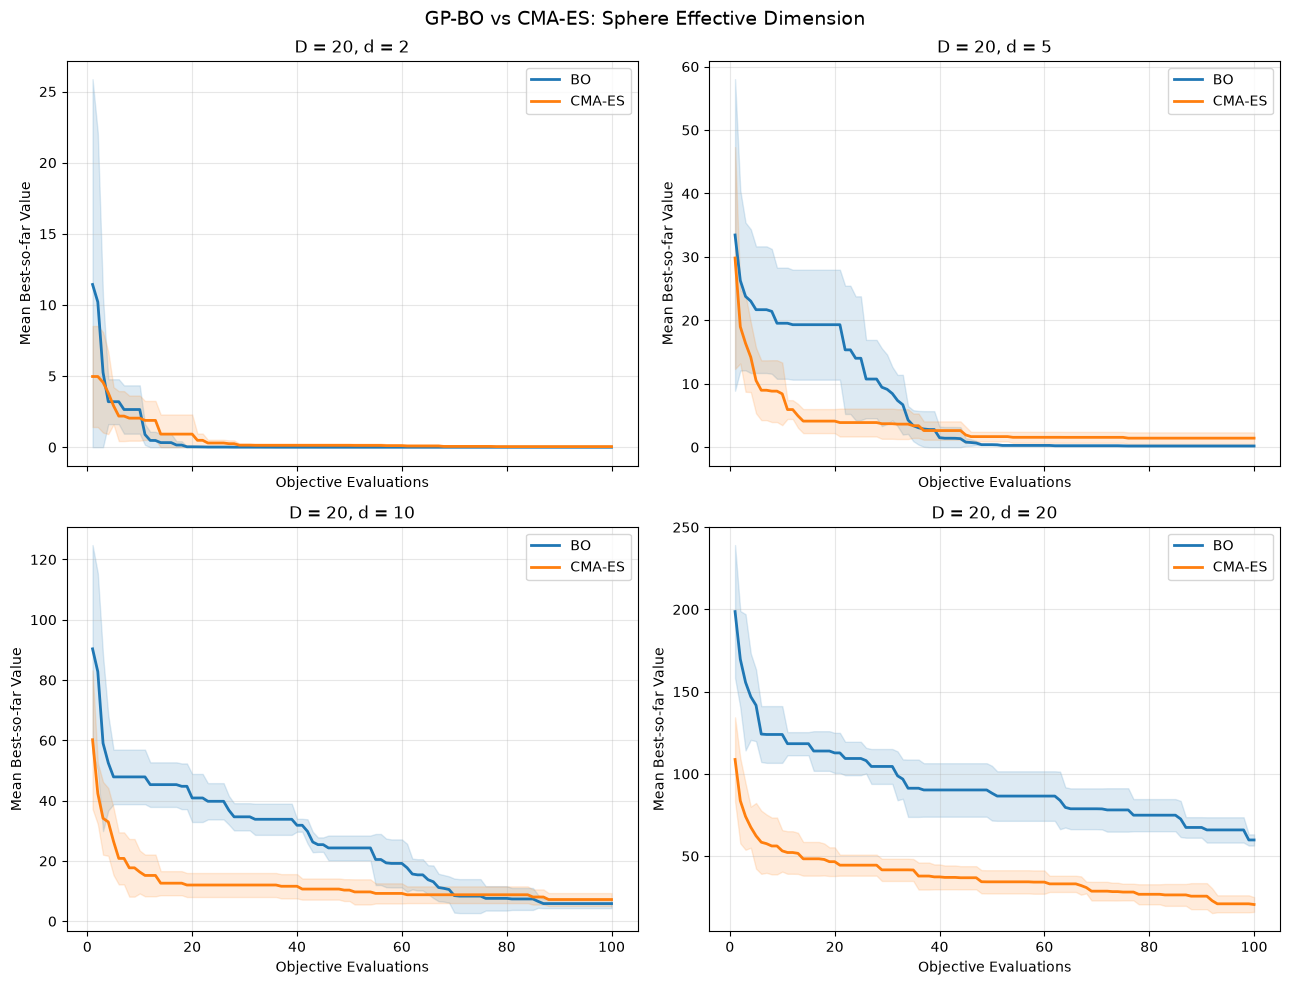

In [21]:

# ============================================================
# CONVERGENCE PLOTS
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10),
    sharex=True
)

for ax, d in zip(axes.flat, EFFECTIVE_DIMS):

    subset = history_df[
        history_df["d"] == d
    ]

    for algorithm in ["BO", "CMA-ES"]:

        alg_data = subset[
            subset["algorithm"] == algorithm
        ]

        stats = (
            alg_data
            .groupby("evaluation")["best_value"]
            .agg(["mean", "std"])
        )

        x = stats.index.to_numpy()
        mean = stats["mean"].to_numpy()
        std = stats["std"].fillna(0).to_numpy()

        line, = ax.plot(
            x,
            mean,
            label=algorithm,
            linewidth=2
        )

        ax.fill_between(
            x,
            np.maximum(mean - std, 0),
            mean + std,
            color=line.get_color(),
            alpha=0.15
        )

    ax.set_title(f"D = 20, d = {d}")
    ax.set_xlabel("Objective Evaluations")
    ax.set_ylabel("Mean Best-so-far Value")
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "GP-BO vs CMA-ES: Sphere Effective Dimension",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "convergence_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,algorithm,d,mean_best,std_best,median_best,mean_runtime,mean_evaluations
0,BO,2,0.000054,0.000052,0.000050,50.149152,100.0
1,BO,5,0.193169,0.090432,0.204325,46.194208,100.0
2,BO,10,5.863067,1.518336,5.667868,55.975908,100.0
3,BO,20,59.824377,3.393103,57.640511,89.933778,100.0
4,CMA-ES,2,0.041242,0.031956,0.038579,0.062976,100.0
5,CMA-ES,5,1.425864,0.912007,0.893610,0.042812,100.0
6,CMA-ES,10,7.207559,2.144241,6.342828,0.037529,100.0
7,CMA-ES,20,20.575448,4.481199,20.693860,0.060310,100.0


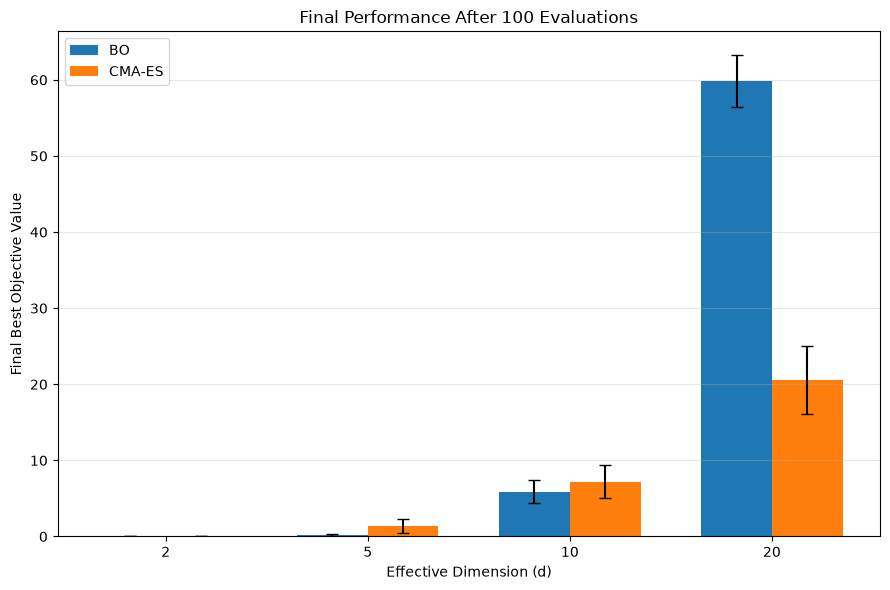

In [22]:

# ============================================================
# FINAL PERFORMANCE SUMMARY
# ============================================================

performance = (
    summary_df
    .groupby(["algorithm", "d"])
    .agg(
        mean_best=("best_value", "mean"),
        std_best=("best_value", "std"),
        median_best=("best_value", "median"),
        mean_runtime=("runtime_seconds", "mean"),
        mean_evaluations=("actual_evaluations", "mean")
    )
    .reset_index()
)

display(performance)

performance.to_csv(
    OUTPUT_DIR / "performance_summary.csv",
    index=False
)

# Plot final best objective values
fig, ax = plt.subplots(figsize=(9, 6))

positions = np.arange(len(EFFECTIVE_DIMS))
width = 0.35

for i, algorithm in enumerate(["BO", "CMA-ES"]):

    data = performance[
        performance["algorithm"] == algorithm
    ].set_index("d").loc[EFFECTIVE_DIMS]

    offset = (i - 0.5) * width

    ax.bar(
        positions + offset,
        data["mean_best"],
        width,
        yerr=data["std_best"],
        capsize=4,
        label=algorithm
    )

ax.set_xticks(positions)
ax.set_xticklabels(EFFECTIVE_DIMS)

ax.set_xlabel("Effective Dimension (d)")
ax.set_ylabel("Final Best Objective Value")
ax.set_title("Final Performance After 100 Evaluations")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "final_performance.png",
    dpi=300
)

plt.show()


In [24]:
# ============================================================
# BENCHMARK RESULTS TABLE
# ============================================================

import pandas as pd

# Load results from existing experiments
results_df = pd.read_csv(
    OUTPUT_DIR / "run_summary.csv"
)

# Rename columns to match reference table
benchmark_table = results_df.rename(columns={
    "best_value": "best",
    "actual_evaluations": "n_evals",
    "runtime_seconds": "total_time"
})

# Rename BO to GP-BO
benchmark_table["algorithm"] = (
    benchmark_table["algorithm"].replace({"BO": "GP-BO"})
)

# Select columns
benchmark_table = benchmark_table[
    ["algorithm", "D", "d", "seed",
     "best", "n_evals", "total_time"]
]

# Sort like the reference table
benchmark_table = (
    benchmark_table
    .sort_values(["algorithm", "D", "d", "seed"])
    .reset_index(drop=True)
)

print("STEP 2: RUNNING BENCHMARKS")
print(benchmark_table.to_string(index=True))

# Save results
benchmark_table.to_csv(
    OUTPUT_DIR / "benchmark_table.csv",
    index=False
)

STEP 2: RUNNING BENCHMARKS
   algorithm   D   d  seed       best  n_evals  total_time
0     CMA-ES  20   2     0   0.077897      100    0.093531
1     CMA-ES  20   2     1   0.038579      100    0.060749
2     CMA-ES  20   2     2   0.069009      100    0.058287
3     CMA-ES  20   2     3   0.015660      100    0.054900
4     CMA-ES  20   2     4   0.005066      100    0.047413
5     CMA-ES  20   5     0   2.808460      100    0.053291
6     CMA-ES  20   5     1   1.911775      100    0.049407
7     CMA-ES  20   5     2   0.798144      100    0.040377
8     CMA-ES  20   5     3   0.893610      100    0.020055
9     CMA-ES  20   5     4   0.717330      100    0.050930
10    CMA-ES  20  10     0   5.846124      100    0.054944
11    CMA-ES  20  10     1   5.673030      100    0.028386
12    CMA-ES  20  10     2  10.871670      100    0.019886
13    CMA-ES  20  10     3   6.342828      100    0.064884
14    CMA-ES  20  10     4   7.304142      100    0.019542
15    CMA-ES  20  20     0  2